In [1]:
%store -r combined_df
combined_df


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
644,MS,F,19,R,GT3,T,2,3,services,other,...,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,...,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,...,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,6,10,10,10


In [2]:
df = combined_df.reset_index(drop=True)


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

In [4]:
print(df.isna().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


In [5]:
df.columns.tolist()

['school',
 'sex',
 'age',
 'address',
 'famsize',
 'Pstatus',
 'Medu',
 'Fedu',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'traveltime',
 'studytime',
 'failures',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic',
 'famrel',
 'freetime',
 'goout',
 'Dalc',
 'Walc',
 'health',
 'absences',
 'G1',
 'G2',
 'G3']

In [6]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance


In [7]:
df = pd.get_dummies(df, drop_first=True, dtype=int)

In [8]:
df = df.drop(columns=["G1", "G2"])      

In [9]:
X = df.drop(columns="G3")
y = df["G3"]

In [10]:
print(df.corr()["G3"].abs().sort_values(ascending=False))


G3                   1.000000
failures             0.393316
higher_yes           0.332172
school_MS            0.284294
studytime            0.249789
Medu                 0.240151
Fedu                 0.211800
Dalc                 0.204719
Walc                 0.176619
reason_reputation    0.170944
address_U            0.167637
internet_yes         0.150025
Mjob_teacher         0.134910
reason_other         0.132577
sex_M                0.129077
traveltime           0.127173
Fjob_teacher         0.125916
freetime             0.122705
age                  0.106505
Mjob_health          0.101244
health               0.098851
absences             0.091379
romantic_yes         0.090583
goout                0.087641
guardian_other       0.080729
schoolsup_yes        0.066405
famrel               0.063361
activities_yes       0.059791
Mjob_other           0.059251
famsup_yes           0.059206
paid_yes             0.054898
Fjob_services        0.053204
reason_home          0.046537
famsize_LE

Even The First 3 correlation values still don't tell us much.
That means we still cannot decide which variables are most associated with the target variable G3. 

I removed G1 and G2 because i want to Understand what drives performance, and since G1 and G2 are also target variables they will be highly correlated.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
rf = RandomForestRegressor(random_state=0).fit(X_train, y_train)

In [12]:
imp = permutation_importance(rf, X_test, y_test, random_state=0)
print(pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False))

failures             0.250813
school_MS            0.040773
higher_yes           0.039215
studytime            0.029031
absences             0.023075
health               0.012521
Dalc                 0.009151
sex_M                0.006966
schoolsup_yes        0.006871
traveltime           0.006868
romantic_yes         0.005834
guardian_other       0.005057
Mjob_other           0.004970
reason_reputation    0.004121
Fjob_teacher         0.003144
guardian_mother      0.002940
nursery_yes          0.002860
activities_yes       0.002613
Fedu                 0.002065
Walc                 0.001961
famsup_yes           0.001845
Pstatus_T            0.001596
Fjob_health         -0.000239
address_U           -0.000682
internet_yes        -0.000702
paid_yes            -0.000958
Fjob_other          -0.001058
age                 -0.001745
famsize_LE3         -0.001812
famrel              -0.001918
Fjob_services       -0.003655
Mjob_health         -0.003669
Mjob_services       -0.003798
reason_hom

Since correlation is sensitive to linear relationships between G3 and the other variables , Permutation importance shows exactly what features are most associated with the Target. 

When Not so sure what the Threshold is:

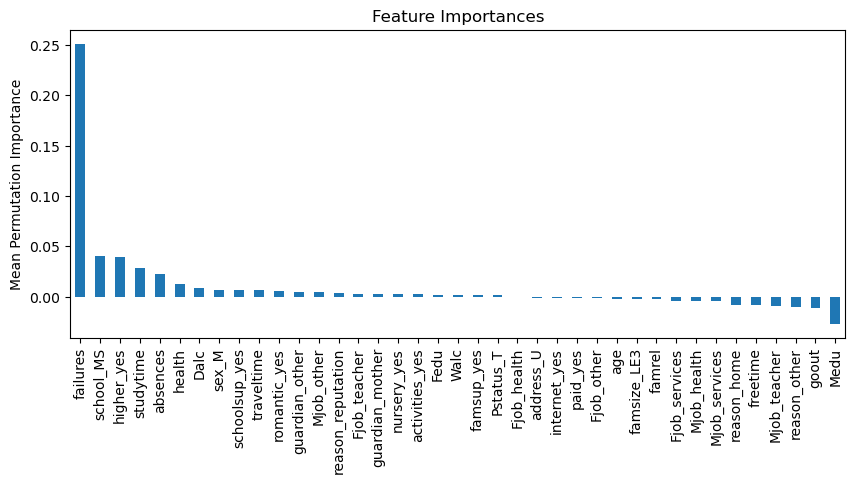

In [13]:
import matplotlib.pyplot as plt

importances = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)
importances.plot(kind='bar', figsize=(10, 4))
plt.ylabel('Mean Permutation Importance')
plt.title('Feature Importances')
plt.show()

The Lasso Method - with a chrinkage parameter

In [15]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score

folds = KFold(n_splits=5, shuffle=True, random_state=0)

lasso = make_pipeline(StandardScaler(), LassoCV(cv=folds))
lasso.fit(X, y)

coefs = pd.Series(lasso[-1].coef_, index=X.columns)
kept = coefs[coefs != 0].sort_values(key=abs, ascending=False)

print(len(kept), "variables kept")
print(kept)

32 variables kept
failures            -0.807410
school_MS           -0.550353
higher_yes           0.515843
schoolsup_yes       -0.349499
studytime            0.319192
sex_M               -0.228300
health              -0.215595
Dalc                -0.188214
Fjob_teacher         0.155340
romantic_yes        -0.145525
reason_other        -0.124083
Fedu                 0.121682
absences            -0.119837
Fjob_services       -0.113160
guardian_mother     -0.109790
Mjob_health          0.109529
address_U            0.108955
age                  0.106978
Walc                -0.105454
freetime            -0.102223
internet_yes         0.099081
Medu                 0.092449
famrel               0.080087
reason_reputation    0.076431
famsize_LE3          0.071712
Mjob_teacher         0.052959
activities_yes       0.049897
paid_yes            -0.043387
Mjob_services        0.033122
goout               -0.021912
Mjob_other          -0.015866
nursery_yes         -0.015012
dtype: float64


In [17]:
from sklearn.linear_model import Lasso

for a in [0.05, 0.1, 0.2, 0.3, 0.5]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a))
    r2 = cross_val_score(m, X, y, cv=folds, scoring="r2").mean()
    n = (m.fit(X, y)[-1].coef_ != 0).sum()
    print("alpha", a, "-> variables:", n, " R2:", round(r2, 3))

alpha 0.05 -> variables: 32  R2: 0.252
alpha 0.1 -> variables: 27  R2: 0.252
alpha 0.2 -> variables: 16  R2: 0.244
alpha 0.3 -> variables: 9  R2: 0.228
alpha 0.5 -> variables: 6  R2: 0.19


In [18]:
from sklearn.linear_model import Lasso

final_model = make_pipeline(StandardScaler(), Lasso(alpha=0.2)).fit(X, y)
c = pd.Series(final_model[-1].coef_, index=X.columns)
final = c[c != 0].sort_values(key=abs, ascending=False)

print(final)

failures            -0.759277
school_MS           -0.476032
higher_yes           0.449052
studytime            0.269986
Dalc                -0.190541
schoolsup_yes       -0.155304
Medu                 0.142992
health              -0.079324
sex_M               -0.072202
Walc                -0.064742
Fedu                 0.062585
reason_reputation    0.039994
reason_other        -0.034640
address_U            0.027443
Fjob_teacher         0.027019
internet_yes         0.006190
dtype: float64
